# Lab 06: How to share tools with MCP

**Notebook 1 of 2: meet MCP on a shopping list**

## Goal

Put two small tools, `add_item` and `list_items`, in a program of their own, an **MCP server**, and watch programs
we did not write use them. We start with a question a model cannot answer: *What is on my shopping list?* We write
the two functions over a text file, move them into a server file, open that file in the MCP Inspector, call it from
Python, and then let the model answer the opening question through it. Nothing here touches the music shop yet. This
notebook is the playground; notebook 2 takes the same idea to the Chinook support desk.

## What you will learn

- Why a tool that lives in one notebook cannot be used by any other program, and what an MCP server changes.
- How to write an MCP server from typed Python functions with `MCPServer` and `@mcp.tool()`.
- How to open a server in the MCP Inspector, from the terminal and in the browser, and call a tool there.
- How to call a server from Python with the official client (`list_tools`, `call_tool`) and read a result's
  `content`, `structuredContent` and `isError`.
- How a host turns an MCP tool into the tool description a model reads, and sends the model's tool call to the
  server.
- How a host repeats those steps in a loop until the model answers, and the names of the pieces: server, client,
  host and transport.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it. This notebook adds `json` and `sys` from Python's standard library.

In [1]:
from pathlib import Path
import json
import os
import sys
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Ask about a list the model cannot see

We start with a question about something that exists only on our own machine:

> What is on my shopping list?

A model can only write from two things: its training data and what we put in the request. Our shopping list is in
neither.

### One model call, no tools

We send the question with the plain OpenAI client, on the Chat Completions API (`client.chat.completions.create`).
It is the basic request-and-reply API: one list of messages goes in, one message comes back.

Two settings go with every model call in this lab: `timeout=60` stops a stuck request after a minute, and
`reasoning_effort=EFFORT or omit` passes the reasoning effort from `models.env`, or leaves it out when there is none.

In [2]:
from openai import OpenAI, omit

client = OpenAI(timeout=60)

QUESTION = "What is on my shopping list?"

response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": QUESTION}],
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)

I don’t have access to your shopping list. If you share it here, I can help review or organize it.


In our run the model answered that it has no access to our shopping list, and offered to help if we paste the
list into the chat.

**Notice:** the model did not make a list up. It has no way to read one, and it said so.

To answer, the model needs something that can read the list, and that something has to be our code.

### Two plain Python functions over a text file

Our shopping list is a text file with one item per line. Two functions are enough to use it:

- `add_item(item)` opens the file in append mode (`"a"`), writes the item and a line break at the end of the file,
  and returns a short sentence saying what it did.
- `list_items()` reads the file and returns the items as a Python list. `splitlines()` cuts the text at every line
  break, so each line becomes one item.

The file goes in `outputs/`, a folder beside this notebook that git ignores. `unlink(missing_ok=True)` deletes a list
left over from an earlier run, so this notebook starts from an empty list every time.

In [3]:
LIST_FILE = ROOT / "06_MCP" / "outputs" / "shopping_list.txt"
LIST_FILE.parent.mkdir(exist_ok=True)
LIST_FILE.unlink(missing_ok=True)


def add_item(item: str) -> str:
    """Add one item to the shopping list."""
    with open(LIST_FILE, "a", encoding="utf-8") as file:
        file.write(item + "\n")
    return f"Added {item}."


def list_items() -> list[str]:
    """List every item on the shopping list, in the order they were added."""
    if not LIST_FILE.exists():
        return []
    return LIST_FILE.read_text(encoding="utf-8").splitlines()

Before any model or server is involved, we call the functions ourselves.

In [4]:
print(add_item("milk"))
print(add_item("eggs"))
print(list_items())

Added milk.
Added eggs.
['milk', 'eggs']


Two items added, and `list_items()` returns them as a list, in the order we added them: `['milk', 'eggs']`.

The file itself is plain text. `repr` shows it with its line breaks written as `\n`:

In [5]:
print(repr(LIST_FILE.read_text(encoding="utf-8")))

'milk\neggs\n'


One item per line, each line ended by `\n`. That file is the whole shopping list.

### Who can use these two functions?

Only this notebook. `add_item` and `list_items` live in the memory of this notebook's Python process:

- **The model cannot reach them.** It runs on OpenAI's servers and never sees our Python.
- **No other program can reach them either.** A second notebook, a chat application on this machine or an
  assistant in a code editor would each need a copy of the code, and three copies soon become three versions.

**MCP**, the Model Context Protocol, is an open standard that closes the second gap. The tools move into a small
program of their own, a **server**. Any program that speaks the protocol can ask the server two things: *which
tools do you have?* and *run this one with these arguments*. Once the tools are in a server, giving them to a model
is a few lines in whichever program holds the conversation (Part E).

**Checkpoint A.** Without a tool the model says it cannot see the shopping list. By hand, `add_item` returns
`Added milk.` and `Added eggs.`, `list_items()` returns `['milk', 'eggs']`, and the file holds `'milk\neggs\n'`.

---

## Part B: Put the same two functions in a server file

A server is a Python file that runs as its own program. This lab comes with `shopping_server.py`, beside this
notebook. We print it before we run it. Starting a server means running its code on your machine with your
permissions, so reading a server first is a habit worth having.

In [6]:
SERVER_FILE = ROOT / "06_MCP" / "shopping_server.py"

print(SERVER_FILE.read_text())

"""A shopping list as an MCP server, run over stdio.

A host starts this file as its own process:
    python 06_MCP/shopping_server.py
It then reads JSON-RPC messages from stdin and writes its replies to stdout, one per line.
"""

from pathlib import Path

from mcp.server import MCPServer

# The list is a text file in outputs/ beside this file, one item per line
LIST_FILE = Path(__file__).resolve().parent / "outputs" / "shopping_list.txt"

mcp = MCPServer("shopping")


@mcp.tool()
def add_item(item: str) -> str:
    """Add one item to the shopping list."""
    LIST_FILE.parent.mkdir(exist_ok=True)
    with open(LIST_FILE, "a", encoding="utf-8") as file:
        file.write(item + "\n")
    return f"Added {item}."


@mcp.tool()
def list_items() -> list[str]:
    """List every item on the shopping list, in the order they were added."""
    if not LIST_FILE.exists():
        return []
    return LIST_FILE.read_text(encoding="utf-8").splitlines()


if __name__ == "__main__":
    mcp.run("st

The two function bodies are the ones we ran in Part A, with one new line in `add_item`:
`LIST_FILE.parent.mkdir(exist_ok=True)` creates `outputs/` if the server is started before this notebook has made
it. Read what else is new, from the top:

- **`LIST_FILE`** is found from the file's own location: `Path(__file__).resolve().parent` is the folder that holds
  `shopping_server.py`. The server opens the same `outputs/shopping_list.txt` as this notebook, whatever folder it is
  started from.
- **`mcp = MCPServer("shopping")`** creates the server object. `MCPServer` comes from `mcp`, the official Python
  package for the protocol, and `"shopping"` is the name the server reports to whoever connects.
- **`@mcp.tool()`** above a function registers it as a tool. The server takes everything it tells the outside
  world from the function itself (the table below).
- **`mcp.run("stdio")`** runs only when the file is started as a program (`if __name__ == "__main__"`). From then
  on the server reads messages from its standard input and writes its replies to its standard output until the
  input closes. This way of carrying the messages is called **stdio**.

What `@mcp.tool()` takes from the function:

| What a caller sees | Where it comes from |
|---|---|
| the tool's name | the function's name (`add_item`) |
| the tool's description | the docstring |
| the arguments it accepts | the typed parameters (`item: str`) |
| the shape of what it returns | the return type (`-> str`, `-> list[str]`) |

Nothing is running yet. The file is a program waiting for someone to start it and send it a message. In Part C that
someone is a program we did not write.

**Checkpoint B.** `shopping_server.py` prints with the two functions of Part A, each under `@mcp.tool()`, one new
line in `add_item` that creates `outputs/`, and `mcp.run("stdio")` at the end.

---

## Part C: Open the server in the MCP Inspector

The **MCP Inspector** is the protocol's own developer tool: a program that connects to any MCP server, lists its
tools and calls them. Nobody who wrote it has seen our file. If it can use our two tools, any program that speaks
MCP can.

The Inspector is a Node.js program, started with `npx`, which downloads it on first use. It has a browser page
and a command-line client. We run the command-line client from this notebook first, so the result is saved here,
then open the page.

⚠️ This part needs Node.js (version 22.19 or newer). Without it the two cells below print one line and skip, and
nothing later in the notebook depends on them: read the saved outputs.

### The Inspector's command-line client

In a terminal the command would be `npx -y @modelcontextprotocol/inspector --cli`, followed by the command that
starts our server, followed by what we want done. From a notebook we start the same program with Python's
`subprocess.run`, which runs a command and gives us what it printed.

The command is a list, read left to right:

- `npx -y @modelcontextprotocol/inspector` fetches the Inspector and starts it (`-y` answers yes to the download);
- `--cli` picks its command-line client;
- `sys.executable` and the path of `shopping_server.py` are the command the Inspector uses to start our server.
  `sys.executable` is the Python that runs this notebook, so the server gets the same environment, with `mcp`
  installed;
- `--method tools/list` is the question: which tools do you have?

`capture_output=True, text=True` gives us what the command printed, as text, in `result.stdout`. The Inspector
prints JSON, and we print two fields of each tool. The first run takes a little longer, while `npx` downloads the
Inspector.

`shutil.which("npx")` looks for `npx` on this machine and returns `None` when it is not installed. Then `HAVE_NPX`
is `False`, and the cell prints the `SKIPPED` line instead of starting the Inspector.

In [7]:
import shutil
import subprocess

# The Inspector's command-line client, and the command it uses to start our server
INSPECTOR = ["npx", "-y", "@modelcontextprotocol/inspector", "--cli", sys.executable, str(SERVER_FILE)]

HAVE_NPX = shutil.which("npx") is not None
SKIPPED = "npx was not found (Node.js is not installed), so this cell is skipped. Read the saved output."

if HAVE_NPX:
    result = subprocess.run(INSPECTOR + ["--method", "tools/list"], capture_output=True, text=True)
    for tool in json.loads(result.stdout)["tools"]:
        print(tool["name"], "|", tool["description"])
else:
    print(SKIPPED)

add_item | Add one item to the shopping list.
list_items | List every item on the shopping list, in the order they were added.


Two tools, `add_item` and `list_items`, each with the docstring we wrote as its description.

**Notice** what happened to get those two lines. The Inspector started `shopping_server.py` as a new process, asked
it for its tools, printed the answer and stopped it. Our notebook's own `add_item` and `list_items` were not
involved.

Now the Inspector calls a tool. `--method tools/call --tool-name list_items` runs `list_items` on the server. This
time we print everything the Inspector printed.

In [8]:
if HAVE_NPX:
    result = subprocess.run(
        INSPECTOR + ["--method", "tools/call", "--tool-name", "list_items"],
        capture_output=True,
        text=True,
    )
    print(result.stdout)
else:
    print(SKIPPED)

{
  "content": [
    {
      "type": "text",
      "text": "milk"
    },
    {
      "type": "text",
      "text": "eggs"
    }
  ],
  "structuredContent": {
    "result": [
      "milk",
      "eggs"
    ]
  },
  "isError": false
}



The result of one tool call, as the server sent it. Three fields:

- **`content`** is a list of blocks. Each block here has type `text`: one block for `milk` and one for `eggs`.
  A tool that returns a list sends one block per item.
- **`structuredContent`** is the same result as data: `{"result": ["milk", "eggs"]}`.
- **`isError`** is `false`: the tool ran and returned.

Milk and eggs are the two items we added by hand in Part A. The server read them from the same text file, in
another process, for a program we did not write.

### The Inspector in the browser

The same tool has a page that makes every step visible. It runs on your own machine.

**Start it.** In a terminal, in the repository folder:

```bash
npx @modelcontextprotocol/inspector uv run python 06_MCP/shopping_server.py
```

Without `uv`, activate the environment and leave `uv run` out. Everything after `inspector` is the command that
starts our server. The Inspector prints an address that begins `http://127.0.0.1:6274` and ends in a long token, and
opens it in your browser. Use exactly that address: the token is what allows the page to start a server on your
machine. When you are done, stop the Inspector with `Ctrl+C` in the terminal.

**Connect.** The page opens on a list with one server, named after the command that starts it and marked
*Disconnected*. Turn on the switch on its row. The top of the page now shows the name our server gave itself,
`shopping`, and three new tabs: *Tools*, *Prompts* and *Resources*.

**Call a tool.** Open *Tools*. The list shows `add_item` and `list_items`. Click `list_items`: its description
is our docstring. Click *Execute Tool*.

*Screenshot to add: the MCP Inspector's Tools tab with `list_items` selected and its result under Results.*

How to read the page:

- **Results** shows `milk` and `eggs`, each in its own box. They are the two `content` blocks of the output above.
- **Structured Output** shows `{"result": ["milk", "eggs"]}`, the `structuredContent`.
- **The column on the right, *Protocol*,** lists every message the Inspector sent to our server, newest first. The
  top one is the `tools/call` for `list_items`. Open a message to read the request and the reply as JSON.

Then click `add_item`. The page shows a form with one field, `item`, built from the function's typed parameter.
Type something you need and execute it. Whatever you add shows up in every later listing in this notebook, after
milk and eggs.

**Which version of the protocol?** The server's row shows `MCP 2025-11-25`. MCP has dated revisions, and by
default the Inspector opens a connection the way the 2025-11-25 revision did. Our server answers that revision and
the newer one, 2026-07-28, which the Python client in Part D uses. The extra notebook in this folder,
`06_extra_on_the_wire.ipynb`, reads the messages of both.

⚠️ The Inspector can start programs on your machine. It listens only on `127.0.0.1`, your own machine, and you
should leave it that way.

**Checkpoint C.** From the notebook, the Inspector lists `add_item` and `list_items` with their descriptions, and
its call to `list_items` returns two text blocks, `milk` and `eggs`, with `isError` `false`. In the browser, the
*Tools* tab lists the same two tools and *Execute Tool* shows the same result. Without Node.js: each of the two
cells prints one line saying it is skipped, and the saved outputs above show what the Inspector prints.

---

## Part D: Call the server from Python with the official client

The Inspector is a tool for people. A program that uses a server asks the same two questions in code. The
`mcp` package has a client for that, and it is what the rest of this notebook uses.

`StdioServerParameters` says how to start the server: the `command` to run and its `args`. They are the same two
things we gave the Inspector. Creating the object starts nothing.

In [9]:
from mcp import Client, StdioServerParameters

SERVER = StdioServerParameters(command=sys.executable, args=[str(SERVER_FILE)])

### Ask the server for its tools

`async with Client(SERVER) as mcp_client:` starts the server process when the block begins and stops it when the
block ends. Inside the block, `list_tools()` asks the first question.

**Why `await`?** The client's methods are `async` functions: calling one only prepares the work, and `await` runs
it and waits for the server's reply. A notebook lets us write `await` and `async with` directly in a cell.

In [10]:
async with Client(SERVER) as mcp_client:
    print("protocol version:", mcp_client.protocol_version)
    listed = await mcp_client.list_tools()

for tool in listed.tools:
    print(tool.name, "|", tool.description)

protocol version: 2026-07-28
add_item | Add one item to the shopping list.
list_items | List every item on the shopping list, in the order they were added.


The same two tools the Inspector listed, this time as Python objects: `listed.tools` is a list of `Tool` objects.
The first line says the client and the server agreed on revision `2026-07-28` of the protocol.

By the time the `for` loop runs, the server process has already stopped, because the `async with` block has ended.
`listed` is an ordinary object in this notebook's memory.

A `Tool` also carries the arguments the tool accepts, as a JSON Schema in `input_schema`. We print it for
`add_item`:

In [11]:
tool = listed.tools[0]

print(tool.name)
print(json.dumps(tool.input_schema, indent=2))

add_item
{
  "type": "object",
  "properties": {
    "item": {
      "title": "Item",
      "type": "string"
    }
  },
  "required": [
    "item"
  ],
  "title": "add_itemArguments"
}


Read the schema from the inside out:

- `properties` has one entry, `item`, of type `string`: that is `item: str` in the function's first line.
- `required` lists `item`: the parameter has no default value, so a caller must send it.
- The two `title` lines are labels the server adds. Nothing we do here reads them.

We did not write this schema. The server built it from the function's type hints, so it cannot drift away from the
function.

### Call a tool and read the result

`call_tool` takes the tool's name and a Python dictionary of arguments. `list_items` takes none, so the dictionary
is empty.

In [12]:
async with Client(SERVER) as mcp_client:
    result = await mcp_client.call_tool("list_items", {})

print(type(result).__name__)
print("content:          ", [block.text for block in result.content])
print("structuredContent:", result.structured_content)
print("isError:          ", result.is_error)

CallToolResult
content:           ['milk', 'eggs']
structuredContent: {'result': ['milk', 'eggs']}
isError:           False


A `CallToolResult`, with the three fields the Inspector printed in Part C:

| Field | What it holds here | Who it is for |
|---|---|---|
| `content` | a list of blocks; we printed the `text` of each: `milk`, `eggs` | the model: a program sends this text back as the tool's result |
| `structuredContent` | `{'result': ['milk', 'eggs']}`, the same result as data | code: a program can read the list without parsing text |
| `isError` | `False`: the tool ran and returned | the calling program, and through it the model |

In Python the fields are spelled `structured_content` and `is_error`. In the protocol's JSON they are
`structuredContent` and `isError`, as the Inspector printed them. The `mcp` package converts between the two.

**Important:** `content` has one block per item, so a list with ten items arrives as ten blocks and an empty list
as none. Code that reads only `content[0]` drops items, and fails on an empty list. Part E joins every block.

Now a call with an argument. We add bread, then read the file from this notebook.

In [13]:
async with Client(SERVER) as mcp_client:
    result = await mcp_client.call_tool("add_item", {"item": "bread"})

print("content:", [block.text for block in result.content])
print("file:   ", LIST_FILE.read_text(encoding="utf-8").splitlines())

content: ['Added bread.']
file:    ['milk', 'eggs', 'bread']


The server answered `Added bread.`, and the file now ends with `bread`. The line was written by the server
process, not by this notebook: we only sent a name and an argument.

**Checkpoint D.** The client reports protocol version `2026-07-28` and lists `add_item` and `list_items`. The schema
of `add_item` has one required string, `item`. `list_items` returns one text block per item and
`{'result': ['milk', 'eggs']}`. After `add_item` with `bread`, the file ends with `bread`.

---

## Part E: Let the model answer through the server

We have a server with the list, and a model that could not see the list in Part A. This part connects them. The
program that does the connecting is called a **host**: it holds the conversation with the model, and it holds an
MCP client for each server it uses. Here the host is the code in this notebook.

A host has two jobs:

1. tell the model which tools exist;
2. when the model asks for one, send the call to the server and give the result back to the model.

### An MCP tool becomes the tool description the model reads

The model never talks to the server. It reads tool descriptions that we put in the request, in the format Chat
Completions expects: a dictionary with a `name`, a `description` and `parameters`. An MCP `Tool` already holds all
three, so the conversion is three assignments.

In [14]:
def to_chat_tool(tool):
    """Turn one MCP tool into the tool description Chat Completions expects."""
    return {
        "type": "function",
        "function": {
            "name": tool.name,
            "description": tool.description,
            "parameters": tool.input_schema,
        },
    }


tools = [to_chat_tool(tool) for tool in listed.tools]

print(json.dumps(tools[0], indent=2))

{
  "type": "function",
  "function": {
    "name": "add_item",
    "description": "Add one item to the shopping list.",
    "parameters": {
      "type": "object",
      "properties": {
        "item": {
          "title": "Item",
          "type": "string"
        }
      },
      "required": [
        "item"
      ],
      "title": "add_itemArguments"
    }
  }
}


Compare this with what we printed in Part D. The `name` is the function's name, the `description` is our
docstring, and `parameters` is the server's `input_schema`, unchanged. The docstring we wrote in
`shopping_server.py` is now the text the model reads to decide whether to ask for the tool.

### The model asks for a tool

The question from Part A again, and this time the request carries `tools=tools`. We print the reply's text and
its tool calls.

In [15]:
messages = [{"role": "user", "content": QUESTION}]

response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=tools,
    reasoning_effort=EFFORT or omit,
)
reply = response.choices[0].message

print("content:  ", reply.content)
for call in reply.tool_calls or []:
    print("tool call:", call.function.name, call.function.arguments)

content:   None
tool call: list_items {}


`content` is `None`: the reply has no text. What it has is one tool call, with the name `list_items` and the
arguments `{}`, an empty JSON object, because `list_items` takes no arguments.

**Notice** what did not happen: nothing ran. The model wrote a request. Whether anything runs is up to our code.

### Our code sends the call to the server

Four steps, all ours:

1. `json.loads` turns the arguments, which arrive as a string of JSON, into a Python dictionary.
2. `call_tool` sends the name and the arguments to the server.
3. We join the `text` of every content block with line breaks. That one string is the tool's result for the model.
4. We add the model's request and our result to `messages` and call the model again. The result is a message with
   the role `tool`, and its `tool_call_id` says which request it answers.

In [16]:
call = reply.tool_calls[0]
arguments = json.loads(call.function.arguments)

async with Client(SERVER) as mcp_client:
    result = await mcp_client.call_tool(call.function.name, arguments)

# Every content block, joined: a list result comes as one block per item
text = "\n".join(block.text for block in result.content)
print("tool result:", repr(text))

messages.append(reply)
messages.append({"role": "tool", "tool_call_id": call.id, "content": text})

response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=tools,
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)

tool result: 'milk\neggs\nbread'


Your shopping list has milk, eggs, and bread.


The tool result is `'milk\neggs\nbread'`: three content blocks joined into one string. The model's answer names
all three items: milk, eggs and bread.

This is the question the model could not answer in Part A. The model is the same. What changed is around it: the
request carried the tool descriptions, our code sent the model's call to the server, and the server read the file.

**Checkpoint E.** The tool description for `add_item` carries our docstring and the server's schema. With
`tools=tools` the model asks for `list_items` and nothing runs. After our code sends the call to the server, the
answer names milk, eggs and bread.

---

## Part F: Run the same steps in a loop, and name the pieces

In Part E we sent one tool call to the server by hand. One question may need several tool calls, and we cannot know
how many in advance. So we repeat: ask the model, send
every call it makes to the server, give the results back, and stop when a reply has no tool call in it.

What `ask` does, step by step:

1. Start the server and ask it for its tools.
2. Send the conversation and the tools to the model.
3. If the reply has no tool calls, it is the answer: return it.
4. Otherwise send each call to the server, print it, and add the result to the conversation.
5. Go back to step 2, at most five times.

`ask` contains `await`, so it is written `async def`, and we call it with `await` too.

In [17]:
async def ask(question, max_turns=5):
    async with Client(SERVER) as mcp_client:
        listed = await mcp_client.list_tools()
        tools = [to_chat_tool(tool) for tool in listed.tools]
        messages = [{"role": "user", "content": question}]

        for turn in range(max_turns):
            response = client.chat.completions.create(
                model=MODEL,
                messages=messages,
                tools=tools,
                reasoning_effort=EFFORT or omit,
            )
            reply = response.choices[0].message
            if not reply.tool_calls:
                return reply.content

            messages.append(reply)
            for call in reply.tool_calls:
                arguments = json.loads(call.function.arguments)
                result = await mcp_client.call_tool(call.function.name, arguments)
                text = "\n".join(block.text for block in result.content)
                print("SERVER CALLED:", call.function.name, arguments)
                messages.append({"role": "tool", "tool_call_id": call.id, "content": text})

    return "No answer after " + str(max_turns) + " turns."

A request that needs both tools. Before you run it: how many `SERVER CALLED` lines will print, and in which order?

In [18]:
answer = await ask(
    "We are out of coffee and I want to bake a cake on Friday, so add coffee, flour and butter "
    "to my shopping list. Then tell me the whole list."
)

print(answer)

SERVER CALLED: add_item {'item': 'coffee'}
SERVER CALLED: add_item {'item': 'flour'}
SERVER CALLED: add_item {'item': 'butter'}


SERVER CALLED: list_items {}


Your shopping list:

- milk
- eggs
- bread
- coffee
- flour
- butter


Four `SERVER CALLED` lines: `add_item` three times, for coffee, flour and butter, then `list_items`. The answer
lists six items.

We asked for three items in one sentence, and the model made three calls. The schema of `add_item` takes one `item`,
so the model split the request to fit the tool.

The answer is text the model wrote. To check what the server did, we read the file:

In [19]:
print(LIST_FILE.read_text(encoding="utf-8").splitlines())

['milk', 'eggs', 'bread', 'coffee', 'flour', 'butter']


Six lines: milk and eggs from Part A, bread from Part D, then coffee, flour and butter, which the model asked for
and the server wrote. (If you added something in the Inspector's page, it is in your list too.)

### The pieces, with their names

Three programs have now used the same server file, and none of them holds a copy of the two functions.

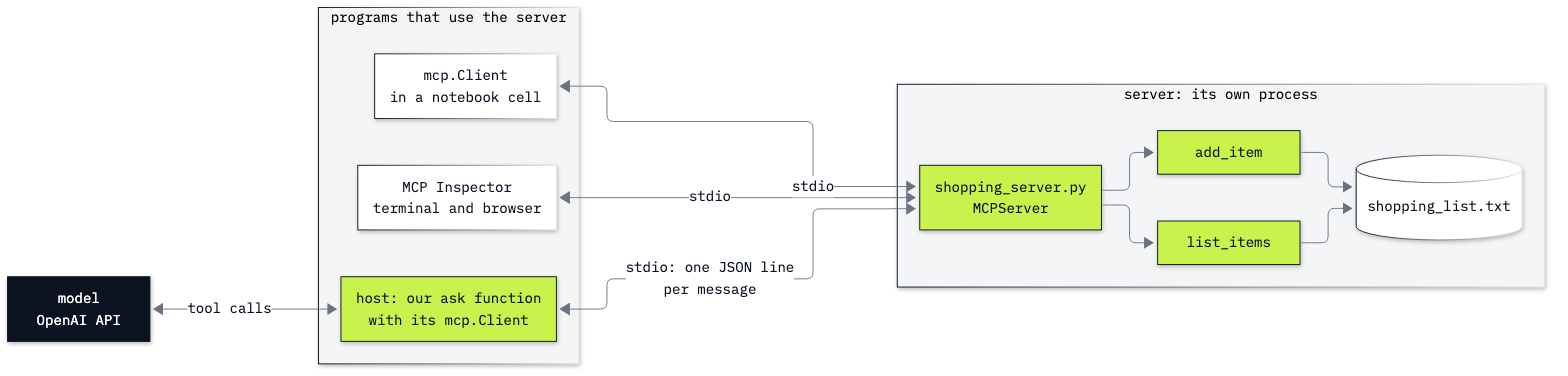

In [20]:
from IPython.display import Image

Image(filename="resources/lab06_shopping_server.png", width=760)

MCP has a word for each piece of the picture:

| Term | What it is | In this notebook |
|---|---|---|
| **server** | a program that offers tools | `shopping_server.py` |
| **client** | the part of a program that speaks MCP to one server | the Inspector's own client; `mcp.Client` in Parts D, E and F |
| **host** | a program that holds the conversation with a model and decides which tool calls to send | our `ask` function |
| **transport** | how the messages travel between client and server | **stdio**: the client starts the server as a process and exchanges lines of JSON with it |

Read the picture from left to right. The model (the dark box) only exchanges messages with the host and never sees the
server. Each of the three programs in the middle started its own copy of `shopping_server.py`, used it and stopped it. The server
and our host (the lime boxes) are the code we wrote. The Inspector is someone else's code, and it used our tools without a
change to either side.

**Key lesson:** MCP did not change who runs a tool. The model still only asks, and the host still decides. What
changed is where the tool's code lives: in one file that any MCP program can start.

**Checkpoint F.** The cake request prints four `SERVER CALLED` lines, three `add_item` and one `list_items`, the
answer lists six items, and the file ends with coffee, flour and butter.

---

## Going further

- **Add the server to a desktop assistant or a code editor.** Many of them are MCP hosts. Each reads a small
  settings file that names the command to start every server. The shape below is the one the MCP documentation
  shows for a desktop assistant; the file's name and place differ per program, so check its own documentation. The
  paths must be full paths on your machine: the Python of this lab's environment, and `shopping_server.py`. After
  a restart of that program, ask it *what is on my shopping list?*

  ```json
  {
    "mcpServers": {
      "shopping": {
        "command": "/full/path/to/.venv/bin/python",
        "args": ["/full/path/to/06_MCP/shopping_server.py"]
      }
    }
  }
  ```

- **A server on another machine.** Stdio is for a server on the same machine as its host. A remote server uses the
  transport called **Streamable HTTP**: the same JSON messages, sent as HTTP requests. The same file can be served
  that way with `mcp.run("streamable-http")`.
- **A server is code you run.** A stdio server from the internet runs on your machine with your permissions, and a
  tool's description is text the model reads and may follow. Read a server before you start it, as we did in
  Part B.
- **The messages themselves.** `06_extra_on_the_wire.ipynb` starts the same server and writes each request by hand.

## What you can do now

- Say why a tool inside one notebook cannot be used by another program, and what moving it into an MCP server
  changes (Parts A and B).
- Write an MCP server from typed functions with `MCPServer` and `@mcp.tool()`, and say where a tool's name,
  description and schema come from (Part B).
- Open a server in the MCP Inspector, list its tools and call one (Part C).
- Call a server from Python with `mcp.Client`, and read `content`, `structuredContent` and `isError` (Part D).
- Turn an MCP tool into the tool description a model reads, and send the model's tool call to the server (Part E).
- Repeat those steps in a loop until the model answers, and name the server, the client, the host and the transport
  (Part F).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `npx was not found (Node.js is not installed), so this cell is skipped.` | the Inspector needs Node.js | install Node.js 22.19 or newer, or read the saved outputs; the other parts do not need it |
| `JSONDecodeError: Expecting value: line 1 column 1 (char 0)` in the first Inspector cell | `npx` could not download or start the Inspector, so it printed nothing | check the network and the Node.js version; `print(result.stderr)` shows the reason |
| `ExceptionGroup: unhandled errors in a TaskGroup (1 sub-exception)` when a `Client` block starts | the server process did not start: a wrong path to the server file, or a Python without `mcp` | start it with `sys.executable` and the path in `SERVER_FILE`; the terminal that runs Jupyter shows the server's own error |
| `TypeError: 'NoneType' object is not subscriptable` at `reply.tool_calls[0]` in Part E | the model answered in text and asked for no tool, so `tool_calls` is `None` | run the cell above it again; the model decides on every run whether to ask |
| `isError: True` and `Field required` in a result | a tool was called without an argument it requires | send the arguments the tool's `input_schema` lists under `required` |
| `SyntaxError: 'await' outside function` in a `.py` file | `await` outside a function works in a notebook only | put the code in `async def main()` and run it with `asyncio.run(main())` |

## Challenge

Give the shopping list a third tool, `remove_item`.

1. Copy `shopping_server.py` to a new file in this folder and add `remove_item(item: str) -> str`. It removes the
   item from the file and returns a sentence saying so, or a sentence saying the item is not on the list. List the
   copy's tools with `mcp.Client`. Expected: three tools, and `remove_item` with one required string, `item`.
2. Point `SERVER` at your copy and ask the model, with `ask`: *I bought the eggs. Take them off my shopping list and
   tell me what is left.* Expected: a `SERVER CALLED` line for `remove_item` with `{'item': 'eggs'}`, an answer
   without eggs, and no `eggs` line in the file.
3. Ask it to remove something that is not on the list. Expected: the model passes on what your tool returned.

`ask` did not change for any of this. The worked solution, run with its outputs, is in
`solved/06a_meet_mcp_solution.ipynb`; its server is `solved/shopping_server_plus.py`.

## Resources

- [What is the Model Context Protocol?](https://modelcontextprotocol.io/docs/2026-07-28/getting-started/intro) and
  the [architecture overview](https://modelcontextprotocol.io/docs/2026-07-28/learn/architecture): hosts, clients
  and servers
- [MCP Python SDK documentation](https://py.sdk.modelcontextprotocol.io/): `MCPServer`, `@mcp.tool()`, `Client`
- [MCP Inspector](https://modelcontextprotocol.io/docs/2026-07-28/tools/inspector): the browser page, the
  command-line client and their options
- [Connect to local MCP servers](https://modelcontextprotocol.io/docs/2026-07-28/develop/connect-local-servers): the
  settings file a desktop assistant reads
- [Local server security](https://modelcontextprotocol.io/docs/2026-07-28/tutorials/security/local-server-security):
  defaults for running servers on your own machine
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool descriptions and
  tool calls on the API

Next: [notebook 2, MCP at the Chinook desk](06b_mcp_at_the_desk.ipynb).